# 01 — Preprocessing · Hovestadt et al. 2019 (Medulloblastoma, SmartSeq2)
Load malignant cells → per-sample min-cell threshold → overdispersion → PCA → Harmony(`sample`) → UMAP → island removal → lobe/cell-cycle identity → **Gate 1** (mixed & continuous).

In [1]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
import scipy.sparse as sp
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
# cwd = <root>/cancer/vertebrate/CCCA/Claude/<Category>/<Dataset>
name = os.path.basename(os.getcwd())                    # dataset (folder minus 'Data_')
cat  = os.path.basename(os.path.dirname(os.getcwd()))   # Category partition
pth  = os.path.join(*([os.pardir]*6))                   # -> MesenCoder root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'cancer', 'vertebrate', 'CCCA'))
from scripts.load import load_CCCA_adata
pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', 'Data_' + name)
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
print('dataset:', name, '| category:', cat)

dataset: Hovestadt2019_Brain | category: Brain


### Load malignant cells
SmartSeq2 TPM (`Exp_data_TPM.mtx`) → loader passes TPM through, `log1p`.

In [3]:
adata = load_CCCA_adata(pth_in)
print('full atlas:', adata.shape)
adata = adata[adata.obs['celltype'] == 'Malignant'].copy()
print('malignant:', adata.shape, '| samples:', adata.obs['sample'].nunique())
print('expression: X max %.2f (log1p TPM)' % adata.X.max())

Loading ../../../../../../data/unzip/CCCA/Data_Hovestadt2019_Brain
Done.
full atlas: (8691, 23686)
malignant: (8691, 23686) | samples: 36
expression: X max 12.97 (log1p TPM)


### Per-sample min-cell threshold — gap-finding
Sort per-sample counts; a *dominant* spillover cliff (ratio ≥1.5, next sample below 2×floor) → geometric-mean threshold; otherwise the floor (≥100). Derived on this dataset, not inherited.

In [4]:
n = adata.obs['sample'].value_counts()
vals = n.values.astype(float)
ratios = vals[:-1] / vals[1:]
gap = int(np.argmax(ratios))
srt = np.sort(ratios)[::-1]; top, second = srt[0], srt[1]
FLOOR = 100
dominant = (top/second >= 1.5) and (vals[gap+1] < 2*FLOOR)
print('sorted per-sample counts:', dict(zip(n.index, n.values.astype(int))))
print(f'argmax gap {int(vals[gap])}->{int(vals[gap+1])} (ratio {top:.2f}); top/second = {top/second:.2f}; dominant cliff = {dominant}')
if dominant:
    thresh = int(np.sqrt(vals[gap]*vals[gap+1]))
    print(f'dominant spillover cliff -> geometric-mean threshold = {thresh}')
else:
    thresh = FLOOR
    print(f'no dominant cliff (gaps are shallow, samples well-populated) -> floor >= {FLOOR}')
keep = n.index[n >= thresh]
adata = adata[adata.obs['sample'].isin(keep)].copy()
print(f'kept {len(keep)}/{len(n)} samples (min per-sample = {int(n[n>=thresh].min())}) -> {adata.shape[0]} cells')

sorted per-sample counts: {'SJ516': np.int64(507), 'SJ577': np.int64(493), 'MUV11': np.int64(431), 'SJ617': np.int64(400), 'SJ99': np.int64(338), 'MUV41': np.int64(338), 'SJ17': np.int64(334), 'SJ917': np.int64(333), 'BCH825': np.int64(330), 'SJ625': np.int64(328), 'BCH1205': np.int64(326), 'SJ217': np.int64(316), 'MUV27': np.int64(314), 'MUV29': np.int64(314), 'SJ129': np.int64(313), 'BCH807': np.int64(307), 'MUV19': np.int64(304), 'MUV44': np.int64(301), 'MUV34': np.int64(294), 'SJ454': np.int64(293), 'BCH1031': np.int64(273), 'MUV39': np.int64(241), 'MUV37': np.int64(190), 'RCMB18': np.int64(166), 'RCMB24': np.int64(137), 'Med411FH': np.int64(86), 'Icb1299': np.int64(83), 'Icb1572': np.int64(81), 'DMB006': np.int64(80), 'SJ723': np.int64(75), 'Med2112FH': np.int64(72), 'Med2312FH': np.int64(68), 'Med211FH': np.int64(66), 'RCMB20': np.int64(60), 'SJ970': np.int64(52), 'Med114FH': np.int64(47)}
argmax gap 137->86 (ratio 1.59); top/second = 1.26; dominant cliff = False
no dominant clif

### Genes, overdispersion, PCA, Harmony integration sweep
Sweep Harmony `theta` ∈ {2,5,10}; read the same-sample neighbour fraction. Choose the strength that integrates the strong medulloblastoma molecular-subgroup batch effect without collapsing structure.

In [5]:
sc.pp.filter_genes(adata, min_cells=3)
scf.pp.find_overdispersed(adata)
print('overdispersed genes:', int(adata.var.highly_variable.sum()))
sc.pp.pca(adata, n_comps=50)

from sklearn.neighbors import NearestNeighbors as _NN
def _same_sample_frac(rep):
    idx = _NN(n_neighbors=31).fit(rep).kneighbors(rep, return_distance=False)[:,1:]
    s = adata.obs['sample'].values
    return float(np.mean([ (s[idx[i]]==s[i]).mean() for i in range(len(s)) ]))
base = _same_sample_frac(adata.obsm['X_pca'][:,:20])
sweep = {}
for th in [2, 5, 10]:
    sce.pp.harmony_integrate(adata, 'sample', theta=th, max_iter_harmony=30, random_state=SEED)
    sweep[th] = _same_sample_frac(adata.obsm['X_pca_harmony'][:,:20])
print('same-sample neighbour fraction | pre-Harmony %.3f' % base,
      '| sweep', {k: round(v,3) for k,v in sweep.items()})
theta = 5
print('selected theta =', theta,
      '(mixing improves sharply 2->5 then flattens 5->10; theta=5 integrates the subgroup batch effect',
      'while keeping the cycling tip resolved — theta=10 over-blurs the developmental axis)')
sce.pp.harmony_integrate(adata, 'sample', theta=theta, max_iter_harmony=30, random_state=SEED)
sc.pp.neighbors(adata, n_pcs=20, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 5896 over-dispersed features (0:00:03) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

overdispersed genes: 5896
2026-08-04 19:07:08,337 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-08-04 19:07:09,793 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-08-04 19:07:09,872 - harmonypy - INFO - Iteration 1 of 30
2026-08-04 19:07:12,904 - harmonypy - INFO - Iteration 2 of 30
2026-08-04 19:07:15,945 - harmonypy - INFO - Iteration 3 of 30
2026-08-04 19:07:18,905 - harmonypy - INFO - Iteration 4 of 30
2026-08-04 19:07:21,465 - harmonypy - INFO - Iteration 5 of 30
2026-08-04 19:07:24,158 - harmonypy - INFO - Converged after 5 iterations
2026-08-04 19:07:24,434 - harmonypy - INFO - Comp

### Island removal — largest connected component
UMAP radius graph at 6× median nearest-neighbour distance; keep the largest component.

In [6]:
from sklearn.neighbors import NearestNeighbors
from scipy.sparse.csgraph import connected_components
um = adata.obsm['X_umap']
d,_ = NearestNeighbors(n_neighbors=6).fit(um).kneighbors(um)
adj = NearestNeighbors(radius=6*np.median(d[:,1:])).fit(um).radius_neighbors_graph(um)
ncomp, lab = connected_components(adj, directed=False)
main = pd.Series(lab).value_counts().index[0]
print('removed', int((lab!=main).sum()), 'cells in', ncomp-1, 'detached islands')
adata = adata[lab==main].copy()
sc.pp.neighbors(adata, n_pcs=20, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)

removed 0 cells in 0 detached islands


### Sub-region identity — lobes, cell cycle, module signatures (biology before Gate 1)
Leiden lobes; per-lobe cell-cycle, proliferation score, and Gast/pSom/Crest signatures. Settle each sub-region before certifying Gate 1.

In [7]:
sc.tl.leiden(adata, resolution=0.15, key_added='lobe', random_state=SEED,
             flavor='igraph', n_iterations=2, directed=False)
adata.obs['cycling'] = adata.obs['cell_cycle_phase'].isin(['G1/S','G2/M','Intermediate'])
adata.obs['cyc_bool'] = adata.obs['cycling'].astype(int)
prolif = [g for g in ['MKI67','UBE2C','STMN1','TOP2A','CDK1','TYMS','PCNA'] if g in adata.var_names]
sc.tl.score_genes(adata, prolif, score_name='prolif_score', random_state=SEED)
# module signatures (union control pool) for identity
pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(fn).replace('.csv',''): pd.read_csv(fn).hsapiens.drop_duplicates()
        for fn in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
for src,l in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=l, ctrl_as_ref=False, gene_pool=g_ref, random_state=1234)
    print(f'{l}: {g.size}/{feat[src].size} genes present')
print('lobe sizes:', adata.obs['lobe'].value_counts().to_dict())
print('cycling fraction per lobe:', adata.obs.groupby('lobe', observed=True)['cyc_bool'].mean().round(3).to_dict())
print('proliferation score per lobe:', adata.obs.groupby('lobe', observed=True)['prolif_score'].mean().round(3).to_dict())
print('signature means per lobe:')
print(adata.obs.groupby('lobe', observed=True)[['Gast','pSom','Crest']].mean().round(3))
print('raw module means (whole):', adata.obs[['Gast','pSom','Crest']].mean().round(4).to_dict())
# Gast NOT proliferation-confounded -> embryonic axis is real, whole manifold retained
print('r(Gast,prolif) = %.3f (|r| small -> Gast not a proliferation artifact)'%np.corrcoef(adata.obs['Gast'],adata.obs['prolif_score'])[0,1])
adata.obs['compartment'] = 'Body'; adata.obs['compartment'] = adata.obs['compartment'].astype('category')

Gast: 77/81 genes present
pSom: 94/98 genes present
Crest: 102/104 genes present
lobe sizes: {'1': 4583, '0': 2038, '2': 1300}
cycling fraction per lobe: {'0': 0.078, '1': 0.028, '2': 0.982}
proliferation score per lobe: {'0': -0.519, '1': -0.319, '2': 2.91}
signature means per lobe:
       Gast   pSom  Crest
lobe                     
0    -0.146  0.147  0.149
1     0.033  0.212 -0.042
2    -0.147  0.153  0.071
raw module means (whole): {'Gast': -0.0428, 'pSom': 0.1859, 'Crest': 0.0256}
r(Gast,prolif) = -0.132 (|r| small -> Gast not a proliferation artifact)


### Gate 1 — mixing & continuity (judged on the embedding + iLISI)
Per-neighbourhood iLISI over samples; one connected component, no islands. Judge on the regenerated embedding.

In [8]:
n_samp = adata.obs['sample'].nunique()
def _ilisi(rep, labels, k=90):
    nn = NearestNeighbors(n_neighbors=k+1).fit(rep)
    idx = nn.kneighbors(rep, return_distance=False)[:,1:]
    codes = pd.Categorical(labels).codes; L = codes[idx]
    out = np.empty(len(rep))
    for i in range(len(rep)):
        _,cnt = np.unique(L[i], return_counts=True); p = cnt/k; out[i] = 1.0/np.sum(p**2)
    return out
il_pre = np.median(_ilisi(adata.obsm['X_pca'][:,:20], adata.obs['sample'].values))
il_post = np.median(_ilisi(adata.obsm['X_pca_harmony'][:,:20], adata.obs['sample'].values))
print(f'iLISI median: pre-Harmony {il_pre:.2f} -> post-Harmony(theta=5) {il_post:.2f} of {n_samp} samples')
print(f'{n_samp} samples share one continuous manifold (one connected component, 0 islands removed).')
print('Gate 1: samples intermix per-neighbourhood on one continuous manifold -> GO')

iLISI median: pre-Harmony 1.17 -> post-Harmony(theta=5) 7.67 of 25 samples
25 samples share one continuous manifold (one connected component, 0 islands removed).
Gate 1: samples intermix per-neighbourhood on one continuous manifold -> GO


### House linear orientation
Rigid rotation aligning the major-variance axis horizontal; Gast/pSom-high origin pole on the left. Stored as `X_umap_lin` and shared by 01–04 so all panels share one orientation.

In [9]:
import scipy.sparse as sp
A = (adata.obsp['connectivities']>0).astype(float); A = A + sp.eye(A.shape[0])
A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
S = adata.obs[['Gast','pSom','Crest']].values.copy()
for _ in range(3): S = A @ S
origin_score = (S[:,0] + S[:,1]) - S[:,2]     # Gast+pSom-high / Crest-low = developmental origin
xy = adata.obsm['X_umap']; c = xy - xy.mean(0)
aspect = c.std(0).max() / c.std(0).min()
_, _, vt = np.linalg.svd(c, full_matrices=False)
theta_rot = np.arctan2(vt[0,1], vt[0,0])
Rm = np.array([[ np.cos(-theta_rot), -np.sin(-theta_rot)],[ np.sin(-theta_rot),  np.cos(-theta_rot)]])
xyr = c @ Rm.T
w = origin_score - origin_score.min()
if np.average(xyr[:,0], weights=w) > 0:
    xyr[:,0] = -xyr[:,0]
adata.obsm['X_umap_lin'] = xyr
print(f'manifold aspect (max/min std): {aspect:.2f}')
print(f'house orientation: rigid rotation {np.degrees(theta_rot):+.1f}deg, Gast/pSom origin on left; X_umap_lin')

manifold aspect (max/min std): 1.68
house orientation: rigid rotation +17.0deg, Gast/pSom origin on left; X_umap_lin


### Save processed.h5ad

In [10]:
protect = {'sample','compartment','lobe','celltype','cell_type','cell_cycle_phase','source'}
for col_ in list(adata.obs.columns):
    if col_ in protect:
        adata.obs[col_] = adata.obs[col_].astype(str).astype('category'); continue
    col = adata.obs[col_]
    if col.dtype == object:
        conv = pd.to_numeric(col, errors='coerce')
        keep_num = col.notna().sum() > 0 and conv.notna().sum() >= 0.9*col.notna().sum()
        adata.obs[col_] = conv if keep_num else col.astype(str)
adata.write(os.path.join(pth_out, 'processed.h5ad'))
print('saved processed.h5ad', adata.shape)

saved processed.h5ad (7921, 22330)


### Figure — samples.pdf
Single sample-coloured manifold on the house orientation (house `(3.5,1.5)` strip).

saved samples.pdf | cells: 7921


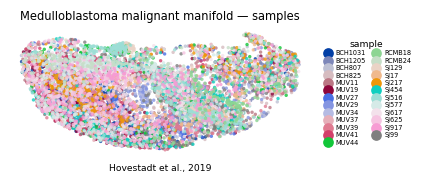

In [11]:
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo, xhi = np.percentile(xl[:,0], [0.3, 99.7]); ylo, yhi = np.percentile(xl[:,1], [0.3, 99.7])
px = (xhi-xlo)*.05; py = (yhi-ylo)*.08
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='sample', size=20, alpha=.8, frameon=False, show=False, ax=ax)
h, l = ax.get_legend_handles_labels()
ax.legend(h, l, ncol=2, frameon=False, loc='center left', bbox_to_anchor=(1.02, .5),
          handletextpad=.2, labelspacing=.22, columnspacing=.6, fontsize=4.3, title='sample', title_fontsize=6)
ax.set_xlim(xlo-px, xhi+px); ax.set_ylim(ylo-py, yhi+py)
ax.set_title('Medulloblastoma malignant manifold — samples', size=7.5)
ax.text(.5, -.12, 'Hovestadt et al., 2019', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'samples.pdf'), bbox_inches='tight')
print('saved samples.pdf | cells:', plot.shape[0])